In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
import kagglehub

In [2]:
os.environ['KAGGLE_API_TOKEN'] = "KGAT_d209809c9109b594505e0d33ed199f1a"
path = kagglehub.dataset_download("carrie1/ecommerce-data")
file_path = os.path.join(path, "data.csv")

100%|██████████| 7.20M/7.20M [00:00<00:00, 76.8MB/s]

Extracting files...


In [5]:
df = pd.read_csv(file_path, encoding='ISO-8859-1')
df = df.dropna(subset=['CustomerID'])
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [6]:
ref_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (ref_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).reset_index()
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

In [7]:
rfm_scaled = StandardScaler().fit_transform(np.log1p(rfm[['Recency', 'Frequency', 'Monetary']]))
pca_features = PCA(n_components=2, random_state=42).fit_transform(rfm_scaled)

In [13]:
rfm['KMeans_Cluster'] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(pca_features)
rfm['DBSCAN_Cluster'] = DBSCAN(eps=0.2, min_samples=15).fit_predict(pca_features)

In [14]:
tsne_features = TSNE(n_components=2, perplexity=40, random_state=42).fit_transform(pca_features)
rfm['tsne_x'] = tsne_features[:, 0]
rfm['tsne_y'] = tsne_features[:, 1]

Text(0.5, 1.0, 'K-Means via t-SNE')

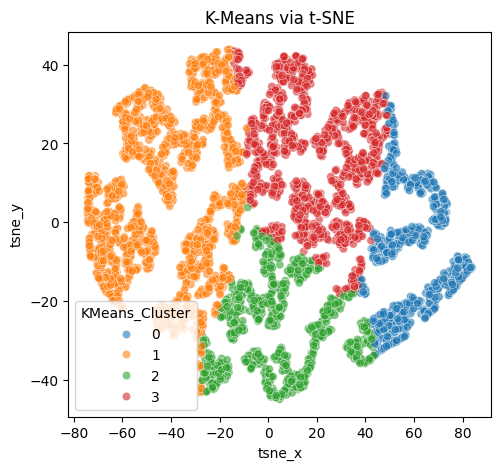

In [15]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(data=rfm, x='tsne_x', y='tsne_y', hue='KMeans_Cluster', palette='tab10', alpha=0.6)
plt.title('K-Means via t-SNE')

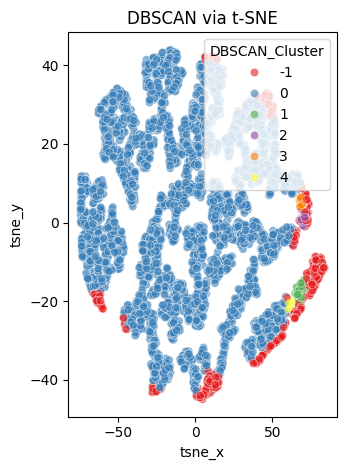

In [16]:
plt.subplot(1, 2, 2)
sns.scatterplot(data=rfm, x='tsne_x', y='tsne_y', hue='DBSCAN_Cluster', palette='Set1', alpha=0.6)
plt.title('DBSCAN via t-SNE')
plt.tight_layout()
plt.show()

In [12]:
print(rfm.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2))

                Recency  Frequency  Monetary
KMeans_Cluster                              
0                 11.57      13.78   8191.66
1                182.67       1.32    364.46
2                 18.62       2.12    530.03
3                 67.43       4.24   1825.24


In [17]:
# DBSCAN Clusters ka RFM Summary
print(rfm.groupby('DBSCAN_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2))

                Recency  Frequency  Monetary
DBSCAN_Cluster                              
-1                39.97      14.54  11322.99
 0                99.55       3.02   1068.08
 1                 3.44      15.21   5575.90
 2                10.71      17.86   7305.74
 3                19.00      16.67   7363.19
 4                 3.67      11.33   3807.20
